In [1]:
import sys
print(sys.executable)   # shows which Python kernel is running
print(sys.version)      # shows Python version


C:\Users\intel\AppData\Local\Python\pythoncore-3.14-64\python.exe
3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


In [3]:
# Import NumPy for numerical arrays and matrix math
import numpy as np

# Import matplotlib to display images
import matplotlib.pyplot as plt

# Import scipy's correlate2d for a reference implementation (to verify our result)
from scipy.signal import correlate2d

# Make matplotlib show images inline in the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Create a dummy 8x8 image.
# Bright 4x4 square in the middle of a dark background —
# makes it easy to see how the filter transforms the image.

image = np.array([
    [  0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0, 255, 255, 255, 255,   0,   0],
    [  0,   0, 255, 255, 255, 255,   0,   0],
    [  0,   0, 255, 255, 255, 255,   0,   0],
    [  0,   0, 255, 255, 255, 255,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0],
], dtype=float)   # use float so arithmetic is easier later

print("Image (8x8):")
print(image)
print("\nImage shape:", image.shape)

Image (8x8):
[[  0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0. 255. 255. 255. 255.   0.   0.]
 [  0.   0. 255. 255. 255. 255.   0.   0.]
 [  0.   0. 255. 255. 255. 255.   0.   0.]
 [  0.   0. 255. 255. 255. 255.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0.]]

Image shape: (8, 8)


In [5]:
# Create a 3x3 filter (kernel).
# This is a Sobel-like VERTICAL edge detector — positive on the left,
# negative on the right. It lights up where brightness changes left→right.

kernel = np.array([
    [ 1,  0, -1],
    [ 2,  0, -2],
    [ 1,  0, -1],
], dtype=float)

print("Kernel (3x3):")
print(kernel)
print("\nKernel shape:", kernel.shape)
print("\nThis kernel detects VERTICAL edges.")

Kernel (3x3):
[[ 1.  0. -1.]
 [ 2.  0. -2.]
 [ 1.  0. -1.]]

Kernel shape: (3, 3)

This kernel detects VERTICAL edges.


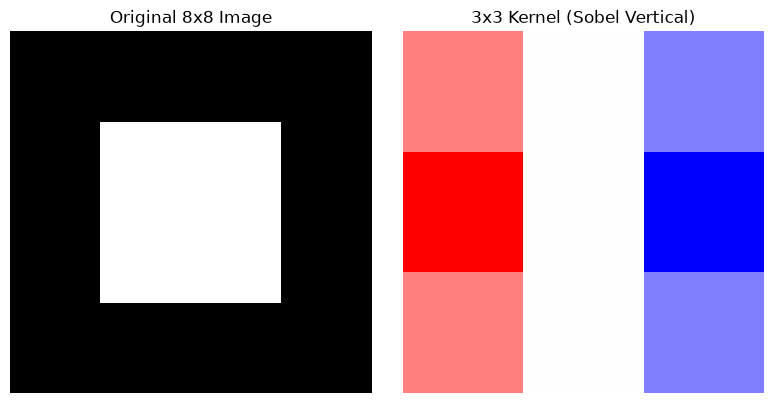

In [6]:
# Create a figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Left: the image
axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original 8x8 Image")
axes[0].axis('off')

# Right: the kernel (blue = negative, red = positive, white = zero)
axes[1].imshow(kernel, cmap='bwr', vmin=-2, vmax=2)
axes[1].set_title("3x3 Kernel (Sobel Vertical)")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [7]:
def conv2d_via_matmul(image, kernel, padding=0):
    """
    Apply a 2D convolution to an image via im2col + matrix multiplication.

    Parameters
    ----------
    image : np.ndarray, shape (H, W)
        The input image (grayscale).
    kernel : np.ndarray, shape (Kh, Kw)
        The filter to apply.
    padding : int
        Zeros added on each side. Use padding = (K - 1) // 2
        to preserve size for odd K.

    Returns
    -------
    out : np.ndarray, shape (out_h, out_w)
        The convolved image.
    """

    # --- Step 1: Pad the image with zeros ---
    padded = np.pad(
        image,
        ((padding, padding), (padding, padding)),
        mode='constant',
        constant_values=0
    )

    # --- Step 2: Get sizes ---
    H, W   = padded.shape       # padded image dimensions
    Kh, Kw = kernel.shape       # kernel dimensions

    # Output size (stride = 1)
    out_h = H - Kh + 1
    out_w = W - Kw + 1

    # --- Step 3: im2col — extract all patches and flatten into rows ---
    patches = []
    for i in range(out_h):          # vertical position
        for j in range(out_w):      # horizontal position
            patch = padded[i:i+Kh, j:j+Kw]      # extract 3x3 patch
            patches.append(patch.flatten())     # flatten to 9-vector

    X_col = np.array(patches)       # shape (out_h*out_w, Kh*Kw)

    # --- Step 4: Flatten the kernel into a column vector ---
    K_col = kernel.flatten().reshape(-1, 1)     # shape (Kh*Kw, 1)

    # --- Step 5: Matrix multiply ---
    out_flat = X_col @ K_col        # shape (num_patches, 1)

    # --- Step 6: Reshape flat result back to 2D image ---
    out = out_flat.reshape(out_h, out_w)

    return out

In [8]:
# Apply our custom convolution function with padding = 1
# Padding = 1 on each side keeps the output at 8x8 (same as input).
output_same = conv2d_via_matmul(image, kernel, padding=1)

print("Output shape (with padding=1):", output_same.shape)
print("\nOutput values:")
print(np.round(output_same, 1))

Output shape (with padding=1): (8, 8)

Output values:
[[    0.     0.     0.     0.     0.     0.     0.     0.]
 [    0.  -255.  -255.     0.     0.   255.   255.     0.]
 [    0.  -765.  -765.     0.     0.   765.   765.     0.]
 [    0. -1020. -1020.     0.     0.  1020.  1020.     0.]
 [    0. -1020. -1020.     0.     0.  1020.  1020.     0.]
 [    0.  -765.  -765.     0.     0.   765.   765.     0.]
 [    0.  -255.  -255.     0.     0.   255.   255.     0.]
 [    0.     0.     0.     0.     0.     0.     0.     0.]]


In [9]:
# Run without padding to see the size shrink
output_valid = conv2d_via_matmul(image, kernel, padding=0)

print("Without padding → shape:", output_valid.shape)   # (6, 6)
print("With padding=1  → shape:", output_same.shape)    # (8, 8)

Without padding → shape: (6, 6)
With padding=1  → shape: (8, 8)


In [10]:
# Use SciPy's correlate2d with mode='same' as an independent check.
reference = correlate2d(image, kernel, mode='same')

# Compare our output with SciPy's
are_equal = np.allclose(output_same, reference)

print("Our output matches SciPy's correlate2d:", are_equal)
# If it prints True, our im2col + matmul approach is correct!

Our output matches SciPy's correlate2d: True


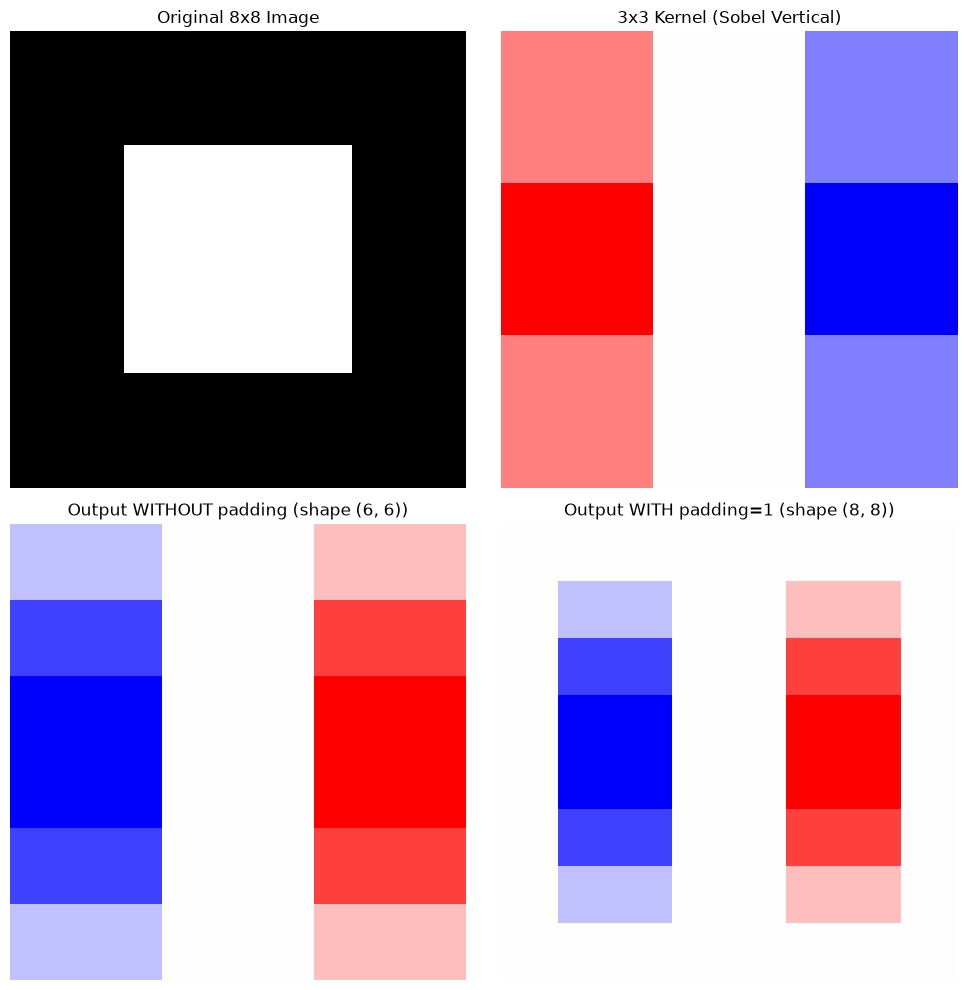

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Top-left: original image
axes[0, 0].imshow(image, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original 8x8 Image")
axes[0, 0].axis('off')

# Top-right: kernel
axes[0, 1].imshow(kernel, cmap='bwr')
axes[0, 1].set_title("3x3 Kernel (Sobel Vertical)")
axes[0, 1].axis('off')

# Bottom-left: output WITHOUT padding (6x6)
axes[1, 0].imshow(output_valid, cmap='bwr')
axes[1, 0].set_title(f"Output WITHOUT padding (shape {output_valid.shape})")
axes[1, 0].axis('off')

# Bottom-right: output WITH padding=1 (8x8)
axes[1, 1].imshow(output_same, cmap='bwr')
axes[1, 1].set_title(f"Output WITH padding=1 (shape {output_same.shape})")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

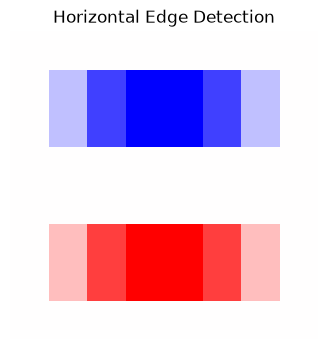

In [12]:
# Try a HORIZONTAL edge detector instead
kernel_horizontal = np.array([
    [ 1,  2,  1],
    [ 0,  0,  0],
    [-1, -2, -1],
], dtype=float)

output_h = conv2d_via_matmul(image, kernel_horizontal, padding=1)

plt.figure(figsize=(4, 4))
plt.imshow(output_h, cmap='bwr')
plt.title("Horizontal Edge Detection")
plt.axis('off')
plt.show()

In [13]:
# This cell shows exactly what the im2col step produces
# so you can see the shape transformation.

# Pad manually
padded = np.pad(image, ((1, 1), (1, 1)), mode='constant', constant_values=0)

# Extract patches
patches = []
for i in range(8):
    for j in range(8):
        patches.append(padded[i:i+3, j:j+3].flatten())
X_col = np.array(patches)

print("Padded image shape:   ", padded.shape)      # (10, 10)
print("im2col matrix shape:  ", X_col.shape)       # (64, 9)
print("Kernel flat shape:    ", kernel.flatten().reshape(-1,1).shape)  # (9, 1)
print("Final output shape:   ", (X_col @ kernel.flatten().reshape(-1,1)).reshape(8,8).shape)  # (8, 8)

# Show the first few rows of the im2col matrix
print("\nFirst 3 rows of the im2col matrix (each row = one 3x3 patch flattened):")
print(X_col[:3])

Padded image shape:    (10, 10)
im2col matrix shape:   (64, 9)
Kernel flat shape:     (9, 1)
Final output shape:    (8, 8)

First 3 rows of the im2col matrix (each row = one 3x3 patch flattened):
[[0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0.]]
